# MSE Budget for hourly releases over New Delhi

25 releases from 25.05.2015 00:00 UTC to 26.05.2015 00:00 UTC are evaluated over 10 days of backward simulation each. In total we are simulating 11 days.

For each release, the particle MSE change is compared with the contributions from sensible and latent surface heat fluxes as well as shortwave and longwave radiation.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import eccodes

In [3]:
################# ONLY CHANGE THIS PATH #####################################

run_dir = Path("/jetfs/scratch/gbrack/flexpart_output/new_delhi_30d_24h_hourly_releases/")

################# DONT CHANGE ANYTHING HERE #################################

grid_files = sorted(run_dir.glob("grid_time*.nc"))
initial_files = sorted(run_dir.glob("partinit_*.nc"))
particle_files = sorted(run_dir.glob("partoutput_*.nc"))
particle_files = [
    path for path in particle_files
    if not path.name.endswith("_init.nc")
]

In [4]:
grid = xr.open_dataset(grid_files[0])
partinit = xr.open_dataset(initial_files[0])
particles = xr.open_mfdataset(particle_files)

In [5]:
release_overview = (
    partinit[["release", "time"]]
    .to_dataframe()
    .groupby("release")
    .agg(
        particles=("time", "size"),
        release_start=("time", "min"),
        release_end=("time", "max")
    )
)

for name in ["spec001_mr", "spec001_s22"]:
    print(name, grid[name].dims, grid[name].attrs.get("units"))

release_overview

spec001_mr ('nageclass', 'pointspec', 'time', 'height', 'latitude', 'longitude') s m3 kg-1
spec001_s22 ('nageclass', 'pointspec', 'time', 'height', 'latitude', 'longitude') s


,particles,release_start,release_end
release,,,
1.0,100000,2015-05-25 00:00:00,2015-05-25 00:00:00
2.0,100000,2015-05-25 01:00:00,2015-05-25 01:00:00
3.0,100000,2015-05-25 02:00:00,2015-05-25 02:00:00
4.0,100000,2015-05-25 03:00:00,2015-05-25 03:00:00
5.0,100000,2015-05-25 04:00:00,2015-05-25 04:00:00
6.0,100000,2015-05-25 05:00:00,2015-05-25 05:00:00
7.0,100000,2015-05-25 06:00:00,2015-05-25 06:00:00
8.0,100000,2015-05-25 07:00:00,2015-05-25 07:00:00
9.0,100000,2015-05-25 08:00:00,2015-05-25 08:00:00


## CALCULATE MSE DIFFERENCE

In [6]:
## CALCULATE MSE

cp = 1004.6 # J / (kg K)
Lv = 2501000 # J / kg
g = 9.81 # m / s^2

def calculate_mse(state):
    longitude = ((state.lon + 180) % 360) - 180

    ground_height = grid.ORO.interp(
        longitude=longitude,
        latitude=state.lat
    )

    temperature_energy = cp * state.T.astype("float64")
    latent_energy = Lv * state.sh.astype("float64")
    potential_energy = g * (state.z.astype("float64") + ground_height)

    return temperature_energy + latent_energy + potential_energy

def calculate_mse_fine(state):
    longitude = ((state.lon + 180) % 360) - 180

    ground_height = grid.ORO.interp(
        longitude=longitude,
        latitude=state.lat
    )

    temperature_energy = cp * state.T.astype("float64")
    latent_energy = Lv * state.sh.astype("float64")
    potential_energy = g * (state.z.astype("float64") + ground_height)

    return xr.Dataset({
        "temperature": temperature_energy,
        "latent": latent_energy,
        "potential": potential_energy
    })

In [7]:
mse_results = []

for release, row in release_overview.iterrows():
    release_time = row["release_start"]
    earlier_time = release_time - pd.Timedelta(days=30)

    particle_ids = partinit.particle.where(partinit.release == release, drop=True)

    release_state = partinit.sel(particle=particle_ids)
    earlier_state = particles.sel(particle=particle_ids, time=earlier_time)

    mse_release = calculate_mse_fine(release_state).compute()
    mse_earlier = calculate_mse_fine(earlier_state).compute()

    valid = (np.isfinite(mse_release).to_array().all(dim="variable") & np.isfinite(mse_earlier).to_array().all(dim="variable"))

    delta_mse = (mse_release - mse_earlier).where(valid).mean(dim="particle", skipna=True)

    mse_results.append({
        "release": int(release),
        "release_time": release_time,
        "valid_particles": int(valid.sum().item()),
        "delta_cpT": delta_mse.temperature.item(),
        "delta_Lvq": delta_mse.latent.item(),
        "delta_pot": delta_mse.potential.item(),
        "delta_mse": delta_mse.to_array().sum(skipna=False).item()
    })

In [8]:
mse_budget = pd.DataFrame(mse_results).set_index("release")
mse_budget

,release_time,valid_particles,delta_cpT,delta_Lvq,delta_pot,delta_mse
release,,,,,,
1,2015-05-25 00:00:00,57962,40976.244150,10453.535762,-50329.960662,1099.819250
2,2015-05-25 01:00:00,57409,40710.566087,11145.483517,-50172.857598,1683.192006
3,2015-05-25 02:00:00,57735,42123.919137,13033.015726,-50292.044224,4864.890640
4,2015-05-25 03:00:00,57649,45243.583651,14335.471784,-50451.020042,9128.035393
5,2015-05-25 04:00:00,57153,48149.856845,14746.705204,-50601.998115,12294.563933
6,2015-05-25 05:00:00,58194,50282.734987,13163.407934,-50326.536011,13119.606910
7,2015-05-25 06:00:00,58454,51583.608854,11099.360741,-50168.771749,12514.197846
8,2015-05-25 07:00:00,57830,53257.299675,8744.856608,-50785.677872,11216.478412
9,2015-05-25 08:00:00,57434,53934.806900,7037.765196,-50467.609267,10504.962829


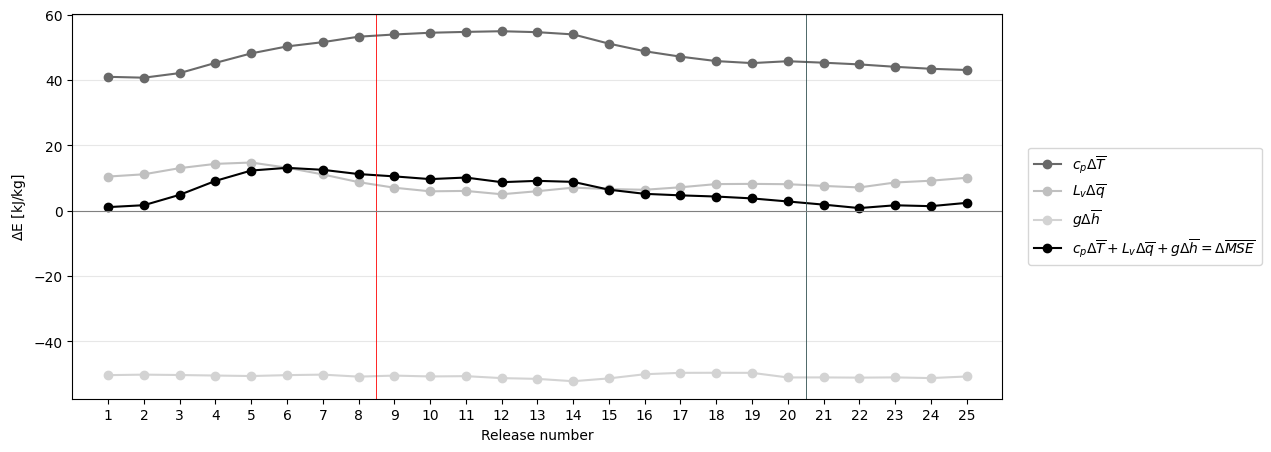

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

plotting_list = [
    ("delta_cpT", r"$c_p \Delta \overline{T}$", "dimgray"),
    ("delta_Lvq", r"$L_v \Delta \overline{q}$", "silver"),
    ("delta_pot", r"$g \Delta \overline{h}$", "lightgray"),
    ("delta_mse", r"$c_p \Delta \overline{T} + L_v \Delta \overline{q} + g \Delta \overline{h} = \Delta \overline{MSE}$", "black")
]

for column, label, color in plotting_list:
    ax.plot(
        mse_budget.index, mse_budget[column] / 1000,
        marker="o", label=label, color=color,
    )

ax.axvline(8.5, color="red", linewidth=0.6)
ax.axvline(20.5, color="darkslategrey", linewidth=0.6)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("Release number")
ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))

Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days')

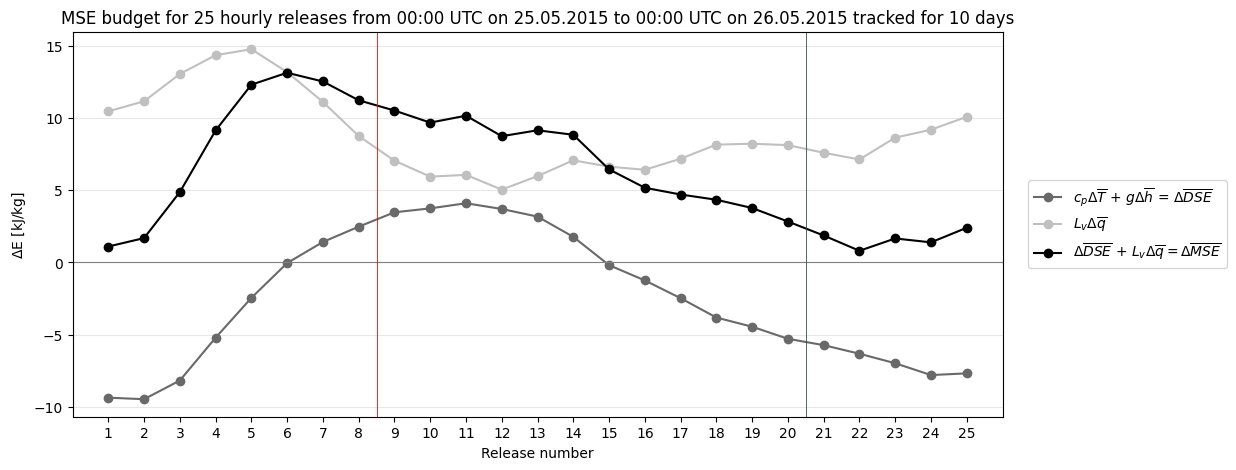

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(mse_budget.index, 
        (mse_budget.delta_cpT + mse_budget.delta_pot) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_mse / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(8.5, color="red", linewidth=0.6)
ax.axvline(20.5, color="darkslategrey", linewidth=0.6)
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_xlabel("Release number")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days")

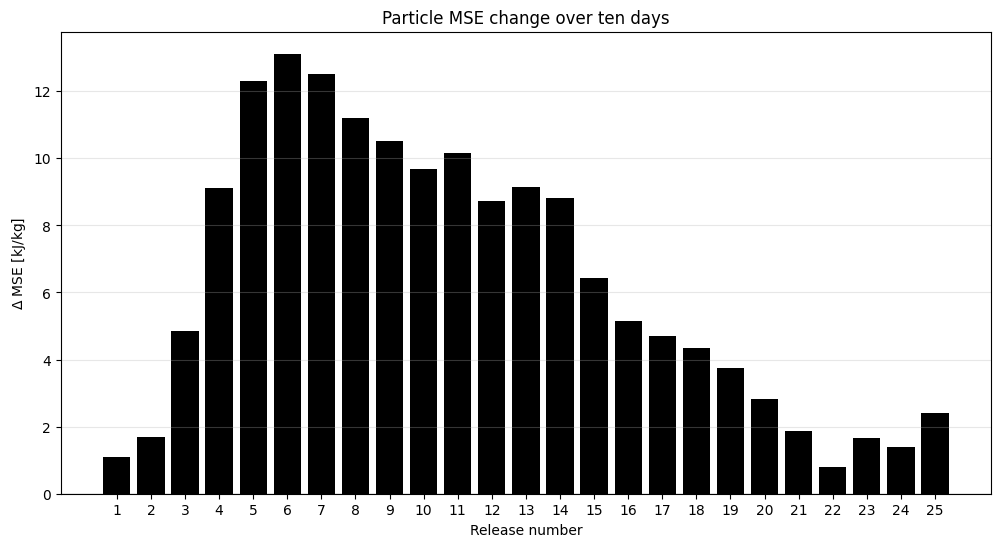

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.bar(mse_budget.index, mse_budget["delta_mse"] / 1000, color="black")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(mse_budget.index)
ax.set_xlabel("Release number")
ax.set_ylabel(r"$\Delta$ MSE [kJ/kg]")
ax.set_title("Particle MSE change over ten days")
ax.grid(axis="y", alpha=0.3)

## SURFACE FLUXES FOR EACH RELEASE

In [24]:
surface_file = Path("/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_2015_04_05_06.nc")
surface = xr.open_dataset(surface_file).rename({"valid_time": "time"})

surface = surface.assign_coords(time=surface.time - np.timedelta64(1, "h"))

surface_aligned = surface.sel(time=grid.time,latitude=grid.latitude,longitude=grid.longitude)

In [25]:
surface_source = xr.Dataset({
    "sensible": -surface_aligned.sshf / (3600 * 100),
    "latent": -surface_aligned.slhf / (3600 * 100)
})

In [ ]:
## calculate surface contribution for each release over the 10 days

surface_results = []

for release, row in release_overview.iterrows():
    release_time = row["release_start"]
    earlier_time = release_time - pd.Timedelta(days=30)

    interval_mask = ((grid.time >= earlier_time) & (grid.time < release_time))

    sensitivity = (
        grid.spec001_mr.isel(pointspec=int(release) - 1, nageclass=0, drop=True).sel(height=100, drop=True).sel(time=grid.time[interval_mask])
    )

    assert sensitivity.sizes["time"] == 240*3  # maximum age of particles

    source = surface_source.sel(time=sensitivity.time)
    source, s = xr.align(source, sensitivity, join="exact")

    contributions = xr.where(s == 0, 0.0, source * s).sum(
        dim=["time", "latitude", "longitude"],
        skipna=False
    ).compute()

    surface_results.append({
        "release": int(release),
        "sensible": contributions.sensible.item(),
        "latent": contributions.latent.item()
    })

surface_budget = pd.DataFrame(surface_results).set_index("release")

mse_budget["sfc_sensible"] = surface_budget["sensible"]
mse_budget["sfc_latent"] = surface_budget["latent"]
mse_budget["sfc_total"] = surface_budget["sensible"] + surface_budget["latent"]

surface_budget

In [46]:
mse_budget

,release_time,valid_particles,delta_cpT,delta_Lvq,delta_pot,delta_mse,sfc_sensible,sfc_latent,sfc_total
release,,,,,,,,,
1,2015-05-25 00:00:00,57962,40976.244150,10453.535762,-50329.960662,1099.819250,NaN,13722.059874,NaN
2,2015-05-25 01:00:00,57409,40710.566087,11145.483517,-50172.857598,1683.192006,NaN,14152.676311,NaN
3,2015-05-25 02:00:00,57735,42123.919137,13033.015726,-50292.044224,4864.890640,NaN,14541.975679,NaN
4,2015-05-25 03:00:00,57649,45243.583651,14335.471784,-50451.020042,9128.035393,NaN,15321.291934,NaN
5,2015-05-25 04:00:00,57153,48149.856845,14746.705204,-50601.998115,12294.563933,NaN,15403.697091,NaN
6,2015-05-25 05:00:00,58194,50282.734987,13163.407934,-50326.536011,13119.606910,NaN,14988.238682,NaN
7,2015-05-25 06:00:00,58454,51583.608854,11099.360741,-50168.771749,12514.197846,NaN,14688.053356,NaN
8,2015-05-25 07:00:00,57830,53257.299675,8744.856608,-50785.677872,11216.478412,NaN,14648.854900,NaN
9,2015-05-25 08:00:00,57434,53934.806900,7037.765196,-50467.609267,10504.962829,NaN,14848.507159,NaN


Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days')

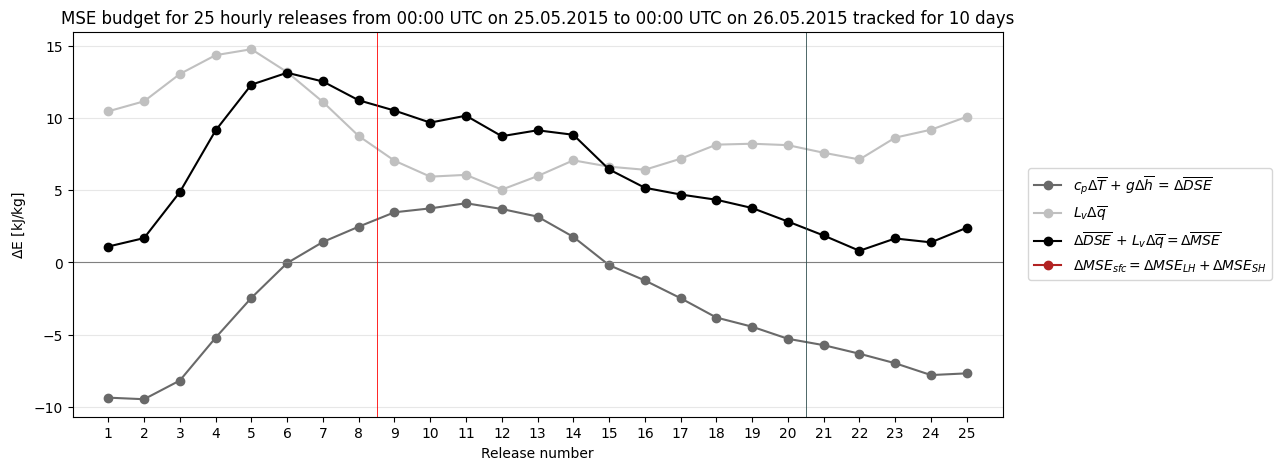

In [47]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(mse_budget.index, 
        (mse_budget.delta_cpT + mse_budget.delta_pot) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_mse / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

ax.plot(mse_budget.index,
        mse_budget.sfc_total / 1000,
        marker="o", label=r'$\Delta MSE_{sfc} = \Delta MSE_{LH} + \Delta MSE_{SH}$', color="firebrick")

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(8.5, color="red", linewidth=0.6)
ax.axvline(20.5, color="darkslategrey", linewidth=0.6)
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_xlabel("Release number")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days")

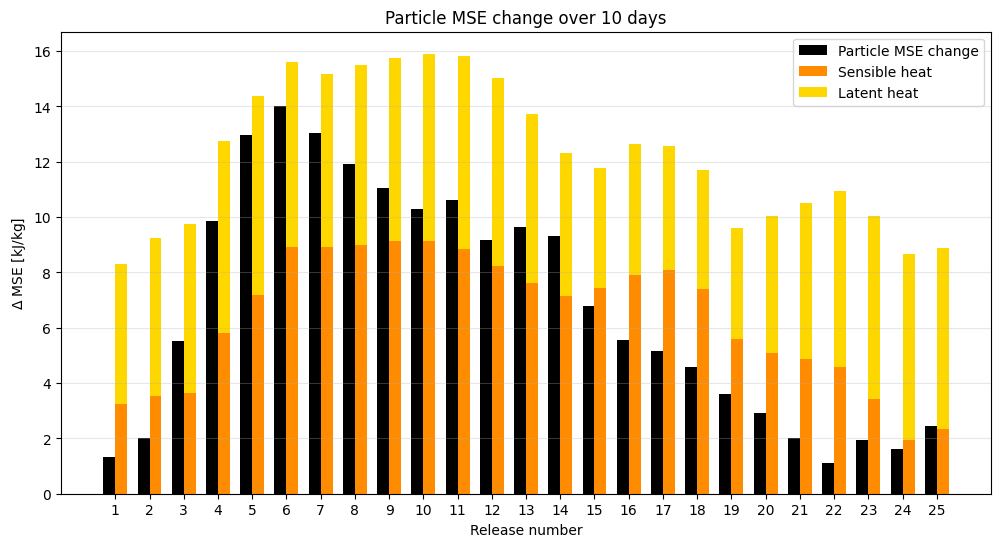

In [13]:
width = 0.35

fig, ax = plt.subplots(1, 1, figsize=(12, 6))
ax.bar(mse_budget.index - width / 2, 
       mse_budget["delta_mse"] / 1000,
       width, 
       label="Particle MSE change", 
       color="black")

ax.bar(mse_budget.index + width / 2, 
       mse_budget["sfc_sensible"] / 1000,
       width, 
       label="Sensible heat", 
       color="darkorange")
ax.bar(mse_budget.index + width / 2, 
       mse_budget["sfc_latent"] / 1000,
       width, 
       bottom=mse_budget["sfc_sensible"] / 1000,
       label="Latent heat", 
       color="gold")

ax.set_xticks(mse_budget.index)
ax.set_xlabel("Release number")
ax.set_ylabel(r"$\Delta$ MSE [kJ/kg]")
ax.set_title("Particle MSE change over 10 days")
ax.grid(axis="y", alpha=0.3)
ax.legend()

## RADIATION FOR EACH RELEASE, NOW WITH OUR NEW SENSITIVITY MEASURE

We use:

$$
\Delta h_{\mathrm{rad}, r} = \sum_{t,k,y,x} S_{22, r} c_p \overline{\dot{T}_{\mathrm{SW}} + \dot{T}_{\mathrm{LW}}}
$$

In [118]:
radiation_dir = Path("/jetfs/scratch/gbrack/MSC/rad_data/2015/05")

radiation = xr.open_mfdataset(radiation_dir.glob("TMTTRAD_*.nc"))

radiation_selected = radiation.sel(
    valid_time=grid.time.values + np.timedelta64(1, "h"),
    latitude=grid.latitude,
    longitude=grid.longitude
)

met_dir = Path("/jetfs/shared-data/ECMWF/ERA5_glob_0.5deg_1h")

In [119]:
def met_file_for(time):
    timestamp = pd.Timestamp(time)
    return met_dir / timestamp.strftime("%Y/%m/EA%Y%m%d%H")

def read_meteorology(time):
    pieces = []

    for parameter in [130, 133, 134, 129]:
        dataset = xr.open_dataset(
            met_file_for(time),
            engine="cfgrib",
            backend_kwargs={
                "filter_by_keys": {
                    "paramId": parameter
                },
                "indexpath": "",
            }
        )

        try:
            selected = select_output_grid(dataset)

            selected = selected.drop_vars(
                "surface",
                errors="ignore"
            )

            pieces.append(selected.load())

        finally:
            dataset.close()

    return xr.merge(
        pieces,
        join="exact",
    ).sortby("hybrid")

def read_hybrid_coefficients(filename):
    with open(filename, "rb") as file:
        while True:
            message = eccodes.codes_grib_new_from_file(file)

            if message is None:
                raise ValueError("Kein Temperaturfeld gefunden.")

            try:
                parameter = eccodes.codes_get(
                    message, "paramId"
                )

                if parameter == 130:
                    coefficients = np.asarray(
                        eccodes.codes_get_array(message, "pv"),
                        dtype="float"
                    )
                    break
            
            finally:
                eccodes.codes_release(message)

    assert coefficients.size == 276

    a_half = coefficients[:138]
    b_half = coefficients[138:]

    return a_half, b_half

def geometric_altitude(geopotential):
    geopotential_height = geopotential / g0

    return (earth_radius * geopotential_height) / (earth_radius - geopotential_height)


Rd = 287.06
g0 = 9.80665
earth_radius = 6371000.0

def calculate_geometry(met, a_half, b_half):
    met = met.sortby("hybrid")

    temperature = met["t"].transpose(
        "hybrid", "latitude", "longitude"
    ).values.astype("float64")

    humidity = met["q"].transpose(
        "hybrid", "latitude", "longitude"
    ).values.astype("float64")

    surface_pressure = met["sp"].transpose(
        "latitude", "longitude"
    ).values.astype("float64")

    surface_geopotential = met["z"].transpose(
        "latitude", "longitude"
    ).values.astype("float64")

    virtual_temperature = temperature * (
        1.0 + 0.609133 * humidity
    )

    pressure_half = (
        a_half[:, None, None]
        + b_half[:, None, None] * surface_pressure
    )

    geopotential_full = np.empty_like(temperature)
    geopotential_half = np.empty_like(pressure_half)

    geopotential_half[137] = 0.0

    for level in range(137, 0, -1):
        p_lower = pressure_half[level]
        p_upper = pressure_half[level - 1]

        rt = Rd * virtual_temperature[level -1]

        if level == 1:
            dlog_p = np.log(p_lower / 0.1)
            alpha = np.log(2.0)
        else:
            dlog_p = np.log(p_lower / p_upper)

            alpha = 1.0 - (p_upper / (p_lower - p_upper) * dlog_p)

        geopotential_full[level - 1] = (geopotential_half[level] + rt * alpha)
        geopotential_half[level - 1] = (geopotential_half[level] + rt * dlog_p)

    geopotential_half[0] = np.inf

    ground_altitude = geometric_altitude(surface_geopotential)
    height_full = geometric_altitude(surface_geopotential + geopotential_full) - ground_altitude
    
    height_half = np.empty_like(geopotential_half)

    height_half[1:] = geometric_altitude(surface_geopotential + geopotential_half[1:]) - ground_altitude
    height_half[0] = np.inf

    return height_full, height_half

def average_to_flexpart_layers(source, boundaries, upper_bounds):
    layer_means = []
    bottom = 0.0

    for top in upper_bounds:
        overlap = np.maximum(
            0.0,
            np.minimum(boundaries[:-1], top) - np.maximum(boundaries[1:], bottom)
        )

        np.testing.assert_allclose(
            overlap.sum(axis=0),
            top - bottom,
            rtol=1e-8,
            atol=1e-6
        )

        layer_mean = (
            source * overlap
        ).sum(axis=0) / (top - bottom)

        layer_means.append(layer_mean)
        bottom = top

    return np.stack(layer_means)

def select_output_grid(dataset):
    longitude = ((dataset.longitude + 180) % 360) - 180
    dataset = dataset.assign_coords(
        longitude=longitude
    ).sortby("longitude")
    return dataset.sel(latitude=grid.latitude, longitude=grid.longitude)

In [120]:
# TEST for ONE HOUR

test_time = radiation_selected.valid_time.min().values

met_test = read_meteorology(test_time)

a_half, b_half = read_hybrid_coefficients(met_file_for(test_time))

heights_test, boundaries_test = calculate_geometry(met_test, a_half, b_half)

print("time:", test_time)
print("model levels:", heights_test.shape)
print("boundaries:", boundaries_test.shape)

time: 2015-05-15T01:00:00.000000000
model levels: (137, 230, 420)
boundaries: (138, 230, 420)


In [121]:
radiation_test = radiation_selected.sel(valid_time=test_time)

sw_test = radiation_test.avg_ttswr.transpose("model_level", "latitude", "longitude").values
lw_test = radiation_test.avg_ttlwr.transpose("model_level", "latitude", "longitude").values

source_sw_test = average_to_flexpart_layers(cp * sw_test, boundaries_test, grid.height.values)
source_lw_test = average_to_flexpart_layers(cp * lw_test, boundaries_test, grid.height.values)

print("SW:", source_sw_test.shape)
print("LW:", source_lw_test.shape)

SW: (42, 230, 420)
LW: (42, 230, 420)


In [122]:
## SUPER, this works!!

In [123]:
# now lets write a function that makes it easy to calculate the sources for every hour

def radiation_sources_for_hour(interval_end):
    met = read_meteorology(interval_end)

    height_middle, boundaries = calculate_geometry(met, a_half, b_half)

    rad = radiation_selected.sel(valid_time=interval_end)

    sources = {}

    for name, variable in [
        ("sw", "avg_ttswr"),
        ("lw", "avg_ttlwr")
    ]:
        tendency = rad[variable].transpose("model_level", "latitude", "longitude").values

        sources[name] = xr.DataArray(
            average_to_flexpart_layers(cp * tendency, boundaries, grid.height.values),
            dims=("height", "latitude", "longitude"),
            coords={
                "height": grid.height,
                "latitude": grid.latitude,
                "longitude": grid.longitude
            },
            attrs={"units": "J kg-1 s-1"}
        )
    return xr.Dataset(sources)

In [ ]:
# now lets calculate it for every hour and every release
# if a release is not active (has not yet been released or if its particles have been killed)
# the short- and longwave contribution is set to 0, just like with the surface forcing

result_dir = run_dir / "radiation_budget"
result_dir.mkdir(exist_ok=True)

release_times = release_overview["release_start"]
result_files = []

for interval_start in np.sort(grid.time.values):
    interval_end = interval_start + np.timedelta64(1, "h")

    target = result_dir / pd.Timestamp(interval_start).strftime("radiation_%Y%m%d%H.nc")

    if not target.exists():
        active = release_overview.index[
            (release_times - pd.Timedelta(days=30) <= interval_start) & (release_times >= interval_end)
        ].to_numpy(dtype=int)

        sources = radiation_sources_for_hour(interval_end)

        sensitivity = (
            grid.spec001_s22
            .isel(nageclass=0, pointspec=active - 1, drop=True)
            .sel(time=interval_start, drop=True)
            .assign_coords(pointspec=active)
            .rename({"pointspec": "release"})
        )

        contribution = (sources * sensitivity).sum(
            dim=["height", "latitude", "longitude"],
            skipna=False
        ).compute()

        contribution["net"] = contribution["sw"] + contribution["lw"]

        for name in contribution.data_vars:
            contribution[name].attrs["units"] = "J kg-1"

        contribution = contribution.reindex(
            release=mse_budget.index.to_numpy(),
            fill_value=0
        )

        temporary = target.with_suffix(".nc.part")
        contribution.to_netcdf(temporary, engine="netcdf4")
        temporary.replace(target)
    
    result_files.append(target)
    print(f"Fertig: {target.name}", flush=True)

Fertig: radiation_2015051500.nc
Fertig: radiation_2015051501.nc
Fertig: radiation_2015051502.nc
Fertig: radiation_2015051503.nc
Fertig: radiation_2015051504.nc
Fertig: radiation_2015051505.nc
Fertig: radiation_2015051506.nc
Fertig: radiation_2015051507.nc
Fertig: radiation_2015051508.nc
Fertig: radiation_2015051509.nc
Fertig: radiation_2015051510.nc
Fertig: radiation_2015051511.nc
Fertig: radiation_2015051512.nc
Fertig: radiation_2015051513.nc
Fertig: radiation_2015051514.nc
Fertig: radiation_2015051515.nc
Fertig: radiation_2015051516.nc
Fertig: radiation_2015051517.nc
Fertig: radiation_2015051518.nc
Fertig: radiation_2015051519.nc
Fertig: radiation_2015051520.nc
Fertig: radiation_2015051521.nc
Fertig: radiation_2015051522.nc
Fertig: radiation_2015051523.nc
Fertig: radiation_2015051600.nc
Fertig: radiation_2015051601.nc
Fertig: radiation_2015051602.nc
Fertig: radiation_2015051603.nc
Fertig: radiation_2015051604.nc
Fertig: radiation_2015051605.nc
Fertig: radiation_2015051606.nc
Fertig: 

In [167]:
radiation_budget = xr.open_mfdataset(
    result_files,
    combine="nested",
    concat_dim="time",
    join="exact"
).sortby("time")

radiation_totals = radiation_budget.sum(
    dim="time",
    skipna=False,
).compute()

mse_budget["rad_sw"] = radiation_totals.sw.to_series()
mse_budget["rad_lw"] = radiation_totals.lw.to_series()
mse_budget["rad_net"] = radiation_totals.sw + radiation_totals.lw

mse_budget["sources_total"] = (
    mse_budget["sfc_total"] + mse_budget["rad_net"]
)

mse_budget["residual"] = (
    mse_budget["delta_mse"] - mse_budget["sources_total"]
)

mse_budget

,release_time,valid_particles,delta_cpT,delta_Lvq,delta_pot,delta_mse,sfc_sensible,sfc_latent,sfc_total,rad_sw,rad_lw,rad_net,sources_total,residual
release,,,,,,,,,,,,,,
1,2015-05-25 00:00:00,19973,47133.109686,14761.462077,-60578.720688,1315.851075,3241.701871,5069.808370,8311.510242,10910.364865,-19026.606079,-8116.241213,195.269028,1120.582047
2,2015-05-25 01:00:00,19989,46910.864231,15429.363812,-60342.226600,1998.001443,3532.072287,5703.636694,9235.708981,11020.696229,-19060.682333,-8039.986104,1195.722877,802.278566
3,2015-05-25 02:00:00,19991,48435.738825,17456.695822,-60378.114769,5514.319878,3650.605345,6113.796299,9764.401644,10950.041270,-18855.475873,-7905.434603,1858.967041,3655.352837
4,2015-05-25 03:00:00,19984,51196.846301,18661.736868,-60014.998582,9843.584586,5820.951091,6928.815984,12749.767076,11017.657636,-18714.676139,-7697.018503,5052.748573,4790.836013
5,2015-05-25 04:00:00,19975,52925.692876,18818.783239,-58786.648289,12957.827826,7188.576023,7203.033967,14391.609991,11201.453050,-18714.114929,-7512.661879,6878.948112,6078.879715
6,2015-05-25 05:00:00,19984,56397.258060,17449.853417,-59821.348991,14025.762486,8928.233105,6672.961615,15601.194720,11411.209264,-18025.620790,-6614.411526,8986.783194,5038.979292
7,2015-05-25 06:00:00,19888,57115.836293,15305.089041,-59385.031844,13035.893489,8903.940721,6263.951743,15167.892464,11302.525350,-17751.411162,-6448.885812,8719.006652,4316.886838
8,2015-05-25 07:00:00,19833,57301.532978,12625.319525,-57992.283420,11934.569083,8981.598133,6504.680828,15486.278961,11382.412720,-17602.998131,-6220.585411,9265.693550,2668.875533
9,2015-05-25 08:00:00,19831,57392.085291,10830.282298,-57168.188427,11054.179162,9143.995627,6605.413173,15749.408799,11478.172025,-17407.938378,-5929.766353,9819.642447,1234.536715


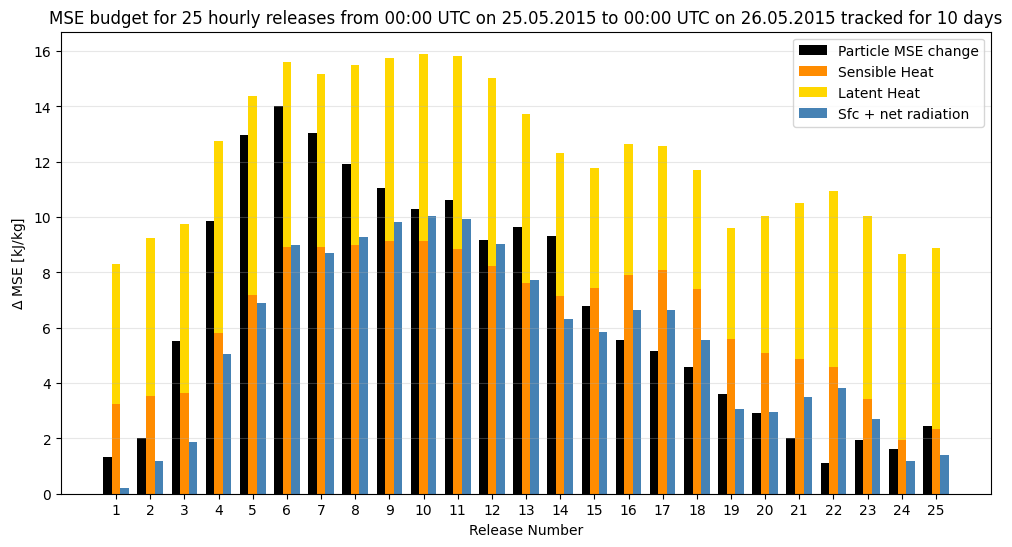

In [126]:
# lets look at it on a bar plot again

width = 0.25

fig, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.bar(
    mse_budget.index - width, mse_budget["delta_mse"] / 1000,
    width, color="black", label="Particle MSE change"
)

ax.bar(
    mse_budget.index, mse_budget["sfc_sensible"] / 1000,
    width, color="darkorange", label="Sensible Heat"
)
ax.bar(
    mse_budget.index, mse_budget["sfc_latent"] / 1000,
    width, bottom=mse_budget["sfc_sensible"] / 1000,
    color="gold", label="Latent Heat"
)

ax.bar(
    mse_budget.index + width, mse_budget["sources_total"] / 1000,
    width, color="steelblue", label="Sfc + net radiation"
)

ax.set_xticks(mse_budget.index)
ax.set_xlabel("Release Number")
ax.set_ylabel(r"$\Delta$ MSE [kJ/kg]")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days")
ax.grid(axis="y", alpha=0.3)
ax.legend()

Text(0.5, 1.0, 'MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days')

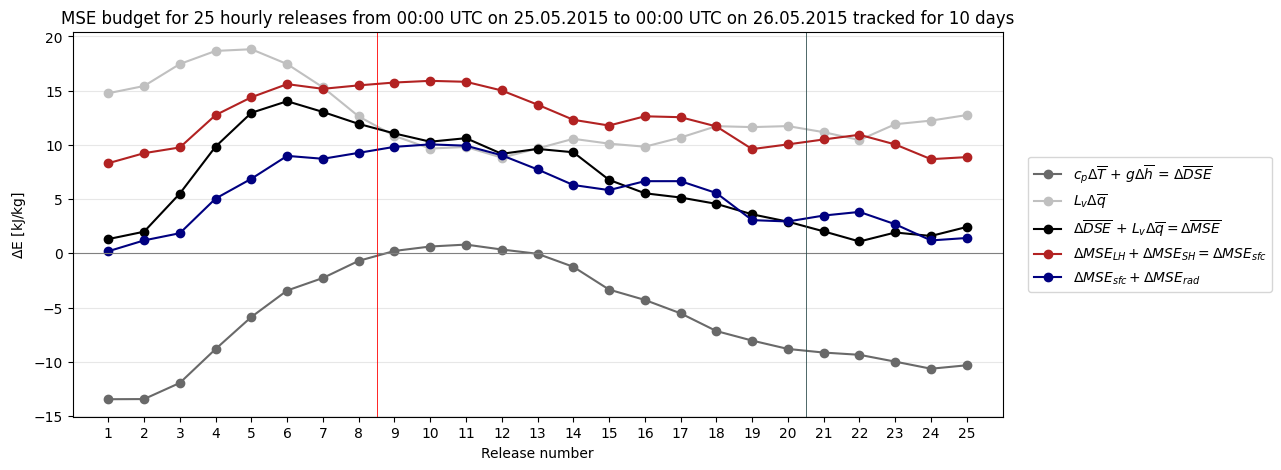

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(mse_budget.index, 
        (mse_budget.delta_cpT + mse_budget.delta_pot) / 1000,
        marker="o", label=r"$c_p \Delta \overline{T}$ + $g \Delta \overline{h}$ = $\Delta \overline{DSE}$", color="dimgray"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_Lvq / 1000,
        marker="o", label=r"$L_v \Delta \overline{q}$", color="silver"
    )

ax.plot(mse_budget.index,
        mse_budget.delta_mse / 1000,
        marker="o", label=r"$\Delta \overline{DSE}$ + $L_v \Delta \overline{q} = \Delta \overline{MSE}$", color="black"
)

ax.plot(mse_budget.index,
        mse_budget.sfc_total / 1000,
        marker="o", label=r"$\Delta MSE_{LH} + \Delta MSE_{SH} = \Delta MSE_{sfc}$", color="firebrick")

ax.plot(mse_budget.index,
        mse_budget.sources_total / 1000,
        marker="o", label=r"$\Delta MSE_{sfc} + \Delta MSE_{rad}$", color="navy")

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(8.5, color="red", linewidth=0.6)
ax.axvline(20.5, color="darkslategrey", linewidth=0.6)
ax.grid(axis="y", alpha=0.3)
ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
ax.set_ylabel(r"$\Delta$E [kJ/kg]")
ax.set_xlabel("Release number")
ax.set_title("MSE budget for 25 hourly releases from 00:00 UTC on 25.05.2015 to 00:00 UTC on 26.05.2015 tracked for 10 days")

Text(0.5, 1.0, 'Residual')

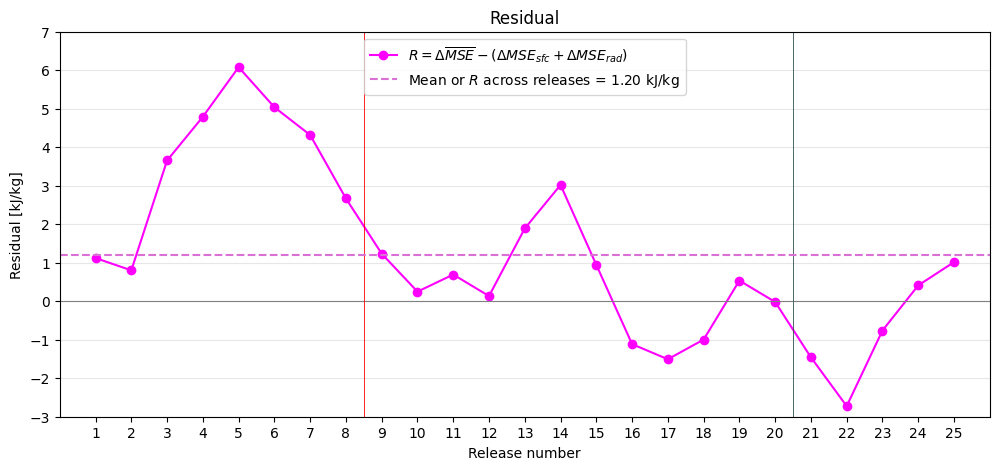

In [185]:
fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(mse_budget.index,
        mse_budget.residual / 1000,
        marker="o", label=r"$R = \Delta \overline{MSE} - (\Delta MSE_{sfc} + \Delta MSE_{rad})$",
        color="magenta"
    )

ax.set_xlim(0, 26)
ax.set_xticks(mse_budget.index)
ax.set_xlabel("Release number")
ax.set_yticks(np.arange(-3, 8, 1))
ax.set_ylim(-3, 7)
ax.set_ylabel("Residual [kJ/kg]")
ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(8.5, color="red", linewidth=0.6)
ax.axvline(20.5, color="darkslategrey", linewidth=0.6)
ax.axhline(mse_budget.residual.mean() / 1000, color="orchid", linestyle="--", label=rf"Mean or $R$ across releases = {(mse_budget.residual.mean() / 1000):.2f} kJ/kg")
ax.grid(axis="y", alpha=0.3)
ax.legend()
ax.set_title("Residual")